# 4. Modèles supervisés et non supervisés

Modèles : régression logistique pondérée et XGBoost (supervisés) ; Isolation Forest, LOF, One-Class SVM, autoencodeur et DBSCAN (non supervisés, entraînés sans étiquette).
Les scores de validation et de test ont été produits par `src/lancer_modeles_supervises.py` et `src/lancer_non_supervise.py`.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

BLEU = "#2a78d6"
ORANGE = "#eb6834"
VERT = "#1baf7a"
JAUNE = "#eda100"
ROSE = "#e87ba4"

In [2]:
from src import evaluation, metriques

jeux = evaluation.charger_scores(RACINE / "donnees")
{nom: jeu.shape for nom, jeu in jeux.items()}

{'validation': (370479, 9), 'test': (370479, 9)}

In [3]:
tableau = evaluation.tableau_comparatif(jeux)
colonnes = ["methode", "jeu", "pr_auc", "roc_auc", "precision_a_k", "rappel_a_k", "alertes", "precision", "rappel", "f2", "mcc", "cout", "economie"]
tableau[colonnes]

,methode,jeu,pr_auc,roc_auc,precision_a_k,rappel_a_k,alertes,precision,rappel,f2,mcc,cout,economie
0,xgboost,validation,0.9171,0.9986,0.6283,0.9237,3763,0.4834,0.9569,0.8001,0.6781,"30,109.1100",0.9696
1,xgboost,test,0.8996,0.9983,0.4905,0.9377,3144,0.4081,0.9511,0.7512,0.6212,"28,907.5400",0.9606
2,logistique,validation,0.4516,0.9151,0.3746,0.5508,8450,0.1520,0.6754,0.3999,0.3139,"136,198.1900",0.8623
3,logistique,test,0.4282,0.9111,0.2935,0.5612,8504,0.1089,0.6864,0.3331,0.2678,"114,360.2200",0.8442
4,isolation_forest,validation,0.1332,0.8995,0.2054,0.3019,21500,0.0602,0.6807,0.2223,0.1913,"201,175.5000",0.7967
5,isolation_forest,test,0.0824,0.8865,0.1330,0.2543,27479,0.0342,0.6968,0.1430,0.1436,"205,128.8200",0.7205
6,one_class_svm,validation,0.1015,0.8313,0.1850,0.2720,27795,0.0381,0.5571,0.1496,0.1314,"357,567.6300",0.6386
7,one_class_svm,test,0.0598,0.8277,0.1136,0.2172,35261,0.0219,0.5715,0.0948,0.0981,"338,670.2100",0.5385
8,autoencodeur,validation,0.0822,0.8307,0.1556,0.2288,17970,0.0570,0.5392,0.2004,0.1640,"305,020.7100",0.6917
9,autoencodeur,test,0.0615,0.8315,0.1090,0.2083,19326,0.0377,0.5397,0.1472,0.1325,"263,556.7600",0.6409


In [4]:
resume = tableau[tableau["jeu"] == "test"].set_index("methode")[["pr_auc", "roc_auc", "precision_a_k", "rappel_a_k"]]
resume.sort_values("pr_auc", ascending=False)

,pr_auc,roc_auc,precision_a_k,rappel_a_k
methode,,,,
xgboost,0.8996,0.9983,0.4905,0.9377
logistique,0.4282,0.9111,0.2935,0.5612
isolation_forest,0.0824,0.8865,0.1330,0.2543
autoencodeur,0.0615,0.8315,0.1090,0.2083
one_class_svm,0.0598,0.8277,0.1136,0.2172
lof,0.0289,0.7106,0.0496,0.0949


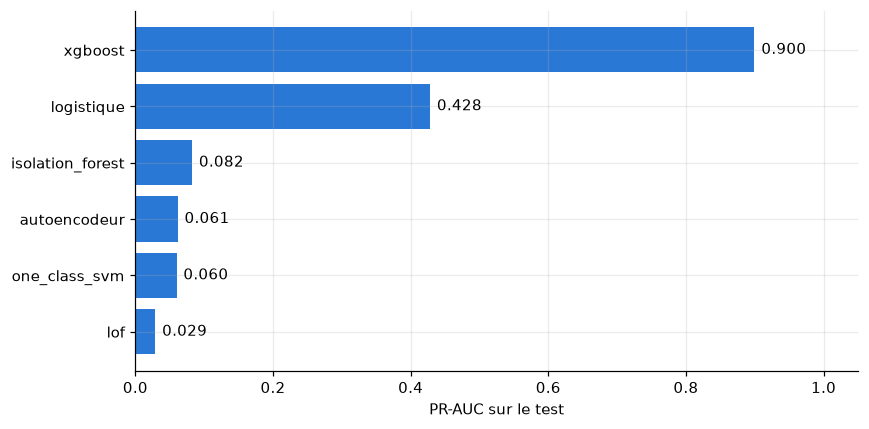

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
test = tableau[tableau["jeu"] == "test"].sort_values("pr_auc")
ax.barh(test["methode"], test["pr_auc"], color=BLEU)
for position, valeur in enumerate(test["pr_auc"]):
    ax.text(valeur + 0.01, position, f"{valeur:.3f}", va="center")
ax.set_xlabel("PR-AUC sur le test")
ax.set_xlim(0, 1.05)
fig.tight_layout()

## Courbes précision-rappel superposées

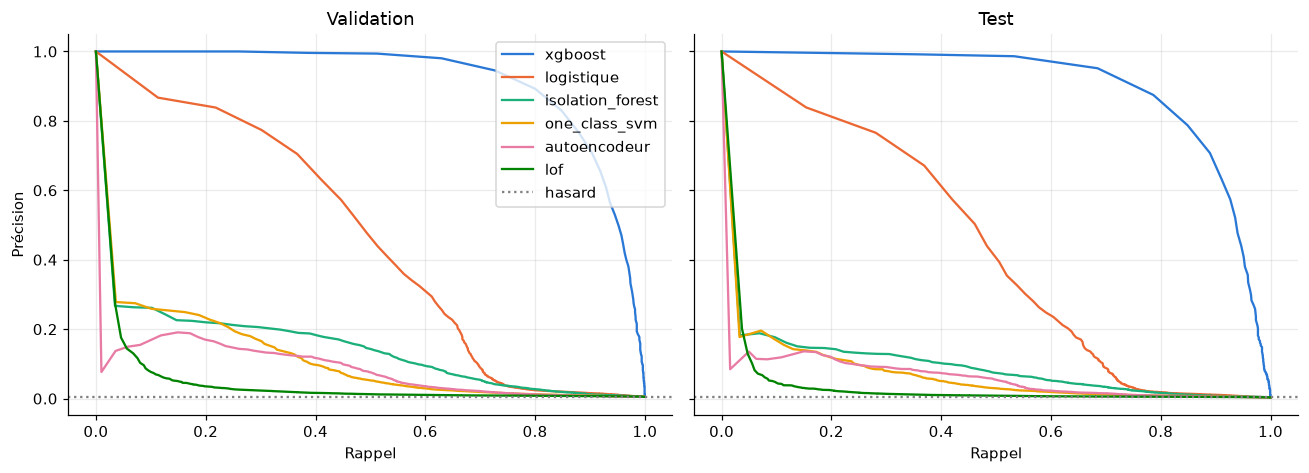

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
couleurs = {"xgboost": BLEU, "logistique": ORANGE, "isolation_forest": VERT, "one_class_svm": JAUNE, "autoencodeur": ROSE, "lof": "#008300"}
for ax, nom in zip(axes, ["validation", "test"]):
    jeu = jeux[nom]
    y = jeu["is_fraud"].to_numpy()
    for methode, couleur in couleurs.items():
        rappel, precision = evaluation.courbe_precision_rappel(jeu, methode)
        ax.plot(rappel, precision, color=couleur, label=methode)
    ax.axhline(y.mean(), color="grey", linestyle=":", label="hasard")
    ax.set_title(nom.capitalize())
    ax.set_xlabel("Rappel")
axes[0].set_ylabel("Précision")
axes[0].legend(loc="upper right")
fig.tight_layout()

## Complémentarité des approches

In [7]:
complementarite = pd.read_csv(RACINE / "resultats" / "complementarite.csv")
complementarite

,jeu,base,appoint,jeu_k,fraudes,detectees_par_base,manquees_par_base,recuperees_par_appoint,alertes_union,rappel_base,rappel_union,rappel_base_au_meme_budget
0,validation,xgboost,isolation_forest,2795,1901,1756,145,15,4681,0.9237,0.9316,0.9663
1,validation,xgboost,one_class_svm,2795,1901,1756,145,12,4848,0.9237,0.9300,0.9700
2,validation,xgboost,autoencodeur,2795,1901,1756,145,12,4906,0.9237,0.9300,0.9700
3,test,xgboost,isolation_forest,2579,1349,1265,84,9,4492,0.9377,0.9444,0.9644
4,test,xgboost,one_class_svm,2579,1349,1265,84,6,4685,0.9377,0.9422,0.9674
5,test,xgboost,autoencodeur,2579,1349,1265,84,5,4651,0.9377,0.9414,0.9659


## Lecture

- Les approches supervisées dominent nettement les approches non supervisées en PR-AUC, ce qui est attendu : elles exploitent les étiquettes.
- Les méthodes non supervisées détectent surtout les montants atypiques ; leur intérêt est de signaler des fraudes qu'aucune étiquette n'a encore décrites.
- LOF, One-Class SVM et DBSCAN sont entraînés sur un échantillon de l'entraînement, leur coût de calcul croissant vite avec le nombre de lignes.
- DBSCAN ne fournit pas de score continu : il désigne des transactions isolées (bruit) mais n'a ni PR-AUC ni courbe précision-rappel.